In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import csv
import pandas as pd
import scipy.io
import numpy as np
import copy


import matplotlib.pyplot as plt
import h5py
import scipy
from PIL import Image
from scipy import ndimage

from tensorflow import keras
import tensorflow as tf

%matplotlib inline
%load_ext autoreload
%autoreload 2

In [3]:
!pip install watermark
%load_ext watermark

%watermark --iversions

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 32.6 MB/s eta 0:00:00
PIL       : 11.2.1
csv       : 1.0
matplotlib: 3.10.0
h5py      : 3.14.0
keras     : 3.8.0
numpy     : 2.0.2
tensorflow: 2.18.0
scipy     : 1.15.3
pandas    : 2.2.2
google    : 2.0.3



#Healthy Unhealthy Classification

In [4]:
data = np.loadtxt('/content/drive/MyDrive/FYP/healthy_unhealthy_classification/dataset/healthy_unhealthy1.csv', delimiter=',')

In [5]:
from sklearn.model_selection import train_test_split

## healthy 0 unhealthy 1
x_bal = data[:,0:1024]
y_bal = data[:,-1]

x_train1, x_test1, y_train1, y_test1 = train_test_split(x_bal, y_bal, test_size = 0.2, shuffle = True)

##1D CNN

In [6]:
# GRADED FUNCTION: convolutional_model
import tensorflow as tf
from keras.callbacks import EarlyStopping
import tensorflow.keras.layers as tfl
import matplotlib.pyplot as plt
from time import time

def convolutional_model(input_shape, x_train,y_train,test_data):
    start = time()
    input_img = tf.keras.Input(shape=input_shape)
    ## CONV1D: 8 filters 4x4, stride of 1, padding 'SAME'
    Z1 = tfl.Conv1D(filters=32,
                    kernel_size=15,
                    strides=1,
                    padding='same')(input_img)
    Z11 = tfl.Conv1D(filters=16,
                    kernel_size=7,
                    strides=1,
                    padding='same')(Z1)
    ## RELU
    A1 = tfl.ReLU()(Z11)
    ## MAXPOOL: window 8x8, stride 8, padding 'SAME'
    P1 = tfl.MaxPool1D(pool_size= 16,
                       padding='same')(A1)


    Z11 = tfl.Conv1D(filters=5,
                    kernel_size=5,
                    strides=1,
                    padding='same',kernel_regularizer=tf.keras.regularizers.L2(0.01))(P1)
    ## RELU
    A1 = tfl.ReLU()(Z11)
    ## MAXPOOL: window 8x8, stride 8, padding 'SAME'
    P1 = tfl.MaxPool1D(pool_size= 4,
                       padding='same')(A1)
    ## CONV2D: 16 filters 2x2, stride 1, padding 'SAME'
    Z2 = tfl.Conv1D(filters=8,
                    kernel_size=5,
                    strides=1,
                    padding='same')(P1)
    Z2=tf.nn.dropout(Z2, rate = 0.3)
    ## RELU
    A2 = tfl.ReLU()(Z2)
    ## MAXPOOL: window 4x4, stride 4, padding 'SAME'
    P2 = tfl.MaxPool1D(pool_size=8,
                       padding='same')(A2)
    ## FLATTEN
    F = tfl.Flatten()(P2)
    ## Dense layer

    op1 = tfl.Dense(units=15,
                       activation='relu', kernel_regularizer=tf.keras.regularizers.L2(0.01))(F)

    #op1= tf.nn.dropout(op1, rate=0.4)

    op = tfl.Dense(units=6,
                        activation='relu')(op1)

    outputs = tfl.Dense(units=1,
                        activation='sigmoid')(op)

    model = tf.keras.Model(inputs=input_img, outputs=outputs)

    #compile
    opt = tf.keras.optimizers.Adam( learning_rate=0.0015, beta_1=0.9, beta_2=0.999, epsilon=1e-07)

    #compile
    model.compile(optimizer = 'adam',
                  loss='binary_crossentropy',
              metrics=['accuracy'])

    model.summary()

    early_stopping = EarlyStopping(monitor='val_loss', patience=100, verbose=2)
    history_m = model.fit(x_train,y_train, epochs=1200, callbacks=[early_stopping], validation_split = 0.2, batch_size = 100, shuffle = True)

    t=time()-start
    print('Total training time:', t)
    history_m.history['time']=t

    return model, history_m



##1D CNN with skip connections



In [7]:
# GRADED FUNCTION: convolutional_model
import tensorflow as tf
from keras.callbacks import EarlyStopping
import tensorflow.keras.layers as tfl
import matplotlib.pyplot as plt
from keras.layers import Dropout # Import Dropout from keras.layers
# from keras.utils.vis_utils import plot_model # Old import
# from keras.layers.merge import concatenate # Old import
from tensorflow.keras.utils import plot_model # New import
from tensorflow.keras.layers import concatenate # New import
from tensorflow import keras
from time import time

def convolutional_model2(input_shape, x_train,y_train,test_data):
    i = 0
    skips = []
    start = time()
    input_img = tf.keras.Input(shape=input_shape)
    ## CONV1D: 8 filters 4x4, stride of 1, padding 'SAME'
    Z11 = tfl.Conv1D(filters=32,
                    kernel_size=7,
                    strides=1,
                    padding='same')(input_img)
    Z12  = tfl.BatchNormalization()(Z11)
    Z13 = tfl.ReLU()(Z12)
    skips.append(Z13)


    Z21 = tfl.Conv1D(filters=32,
                    kernel_size=7,
                    strides=1,
                    padding='same')(Z13)
    Z22  = tfl.BatchNormalization()(Z21)
    Z23 = tfl.ReLU()(Z22)
    Z24 = tfl.Conv1D(filters = 32, kernel_size = 9, strides = 1 , padding = 'same')(Z23)
    skip = skips[i]
    i = i+1
    x = tfl.Concatenate()([Z24, skip])
    skips.append(x)


    Z31  = tfl.BatchNormalization()(x)
    Z32  = tfl.ReLU()(Z31)

    #Z1=tf.nn.dropout(Z1, rate = 0.3)
    Z33 = tfl.Conv1D(filters=16,
                    kernel_size=9,
                    strides=1,
                    padding='same')(Z32)
    Z34 = tfl.MaxPooling1D(pool_size = 2 , padding = 'same')(Z33)
    Z35 = tfl.BatchNormalization()(Z34)
    Z36 = tfl.ReLU()(Z35)

    A1 = tfl.Conv1D(filters=16,
                    kernel_size=9,
                    strides=1,
                    padding='same')(Z36)

    Z41 = tfl.Conv1D(filters=32,
                    kernel_size=7,
                    strides=1,
                    padding='same')(A1)
    Z42  = tfl.BatchNormalization()(Z41)
    Z43 = tfl.ReLU()(Z42)

    skips.append(Z43)


    Z51 = tfl.Conv1D(filters=32,
                    kernel_size=7,
                    strides=1,
                    padding='same')(A1)
    Z52  = tfl.BatchNormalization()(Z51)
    Z53 = tfl.ReLU()(Z52)
    Z54 = tfl.Conv1D(filters = 32, kernel_size = 9, strides = 1 , padding = 'same')(Z53)
    skip = skips[2]
    i = i+1
    x = tfl.Concatenate()([Z54, skip])
    skips.append(x)

    # x = tfl.Concatenate()([Z37, Z42])
    ## RELU
    ## MAXPOOL: window 8x8, stride 8, padding 'SAME'
    P1 = tfl.AveragePooling1D(pool_size= 16,
                       padding='same')(x)
    #P1=tf.nn.dropout(P1, rate = 0.3)


    Z1 = tfl.Conv1D(filters=32,
                    kernel_size=9,
                    strides=1,
                    padding='same')(P1)
    #Z1=tf.nn.dropout(Z1, rate = 0.3)
    Z11 = tfl.Conv1D(filters=12,
                    kernel_size=7,
                    strides=1,
                    padding='same')(Z1)
    ## RELU
    A1 = tfl.ReLU()(Z11)
    ## MAXPOOL: window 8x8, stride 8, padding 'SAME'
    P1 = tfl.MaxPooling1D(pool_size= 8,
                       padding='same')(A1)

    ## CONV2D: 16 filters 3x3, stride 1, padding 'SAME'
    Z2 = tfl.Conv1D(filters=16,
                    kernel_size=5,
                    strides=1,
                    padding='same')(P1)
    #Z2=tf.nn.dropout(Z2, rate = 0.4)
    Z21 = tfl.Conv1D(filters=8,
                    kernel_size=3,
                    strides=1,
                    padding='same')(Z2)
    ## RELU
    A2 = tfl.ReLU()(Z21)
    ## MAXPOOL: window 4x4, stride 4, padding 'SAME'
    P2 = tfl.MaxPooling1D(pool_size=4,
                       padding='same')(A2)

    Z3 = tfl.Conv1D(filters=8,
                    kernel_size=5,
                    strides=1,
                    padding='same')(P2)
    # Changed tf.nn.dropout to tfl.Dropout
    Z3 = tfl.Dropout(rate = 0.2)(Z3)
    Z31 = tfl.Conv1D(filters=4,
                    kernel_size=3,
                    strides=1,
                    padding='same')(Z3)
    ## RELU
    A3 = tfl.ReLU()(Z31)
    ## MAXPOOL: window 8x8, stride 8, padding 'SAME'
    P3 = tfl.MaxPooling1D(pool_size= 4,
                       padding='same')(A3)

    ## FLATTEN
    F = tfl.Flatten()(P3)
    ## Dense layer
    op = tfl.Dense(units=55,
                        activation='relu')(F)

    op1 = tfl.Dense(units=16,
                        activation='relu')(F)


    outputs = tfl.Dense(units=1,
                        activation='sigmoid')(op1)

    model = tf.keras.Model(inputs=input_img, outputs=outputs)

    #compile
    model.compile(optimizer = 'adam',
                  loss='binary_crossentropy',
              metrics=['accuracy'])

    model.summary()

    early_stopping = EarlyStopping(monitor='val_loss', patience=30, verbose=2)
    history_m = model.fit(x_train,y_train, epochs=150, validation_split =0.2, callbacks = [early_stopping], batch_size = 100, shuffle = True)

    t=time()-start
    print('Total training time:', t)
    history_m.history['training_time']=t

    # filepath="/content/drive/MyDrive/ML/Disease_classification/weights/weights-improvement-{epoch:02d}-{val_accuracy:.2f}.hdf5"
    # checkpoint = ModelCheckpoint(filepath, monitor='val_accuracy', verbose=1, save_best_only=True, mode='max')

    return model, history_m

In [8]:
conv_model, history_m = convolutional_model2((1024,1), x_train1, y_train1, (x_test1, y_test1))

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 1024, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 1024, 32)  │        256 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 1024, 32)  │        128 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 1024, 32)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 1024, 32)  │      7,200 │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1024, 32)  │        128 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 1024, 32)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 1024, 32)  │      9,248 │ re_lu_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 1024, 64)  │          0 │ conv1d_2[0][0],   │
│ (Concatenate)       │                   │            │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1024, 64)  │        256 │ concatenate[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 1024, 64)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 1024, 16)  │      9,232 │ re_lu_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 512, 16)   │          0 │ conv1d_3[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512, 16)   │         64 │ max_pooling1d[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 512, 16)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 512, 16)   │      2,320 │ re_lu_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 512, 32)   │      3,616 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512, 32)   │        128 │ conv1d_6[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 512, 32)   │      3,616 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_5 (ReLU)      │ (None, 512, 32)   │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512, 32)   │        128 │ conv1d_5[0][0]  

 Total params: 68,625 (268.07 KB)

 Trainable params: 68,209 (266.44 KB)

 Non-trainable params: 416 (1.62 KB)

Epoch 1/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 31s 86ms/step - accuracy: 0.6720 - loss: 0.6030 - val_accuracy: 0.7323 - val_loss: 0.5019
Epoch 2/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.7538 - loss: 0.4915 - val_accuracy: 0.7526 - val_loss: 0.4824
Epoch 3/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.7647 - loss: 0.4689 - val_accuracy: 0.7378 - val_loss: 0.4898
Epoch 4/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.7715 - loss: 0.4618 - val_accuracy: 0.7752 - val_loss: 0.4617
Epoch 5/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.7724 - loss: 0.4480 - val_accuracy: 0.7468 - val_loss: 0.5298
Epoch 6/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.7718 - loss: 0.4540 - val_accuracy: 0.7523 - val_loss: 0.4528
Epoch 7/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.7784 - loss: 0.4376 - val_accuracy: 0.7821 - val_loss: 0.4249
Epoch 8/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.7843 - loss: 0.4287 -

In [9]:
print(history_m)

In [10]:
conv_model.save('/content/drive/MyDrive/ML/H&U_classification/skip/model_v1.h5')
np.save('/content/drive/MyDrive/ML/H&U_classification/skip/ver1_history.npy',history_m)

# save testdata to csv file
np.savetxt('/content/drive/MyDrive/ML/H&U_classification/skip/xtest_data_ver1.csv', x_test1, delimiter=',')
np.savetxt('/content/drive/MyDrive/ML/H&U_classification/skip/ytest_data_ver1.csv', y_test1, delimiter=',')
np.savetxt('/content/drive/MyDrive/ML/H&U_classification/skip/xtrain_data_ver1.csv', x_train1, delimiter=',')
np.savetxt('/content/drive/MyDrive/ML/H&U_classification/skip/ytrain_data_ver1.csv', y_train1, delimiter=',')

In [13]:
from tensorflow import keras
model1 = keras.models.load_model("/content/drive/MyDrive/ML/H&U_classification/skip/model_v1.h5")

135/135 - 0s - 3ms/step
Accuracy: 0.807176
Specificity: 0.880092
Precision: 0.856517
Sensitivity: 0.732553
F1 score: 0.789700
Cohens kappa: 0.613660
ROC AUC: 0.901781
Total Samples Test:  4320
[[1923  262]
 [ 571 1564]]


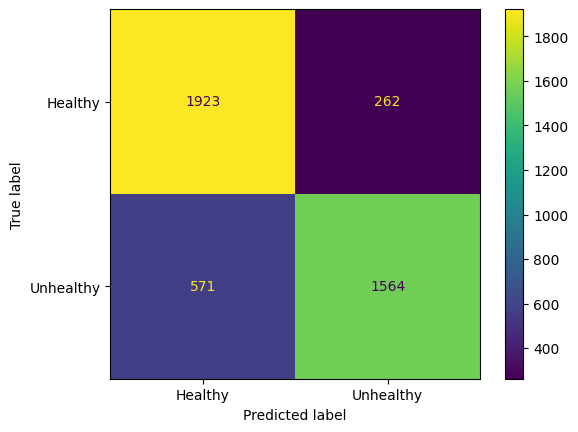

In [15]:
import matplotlib.pyplot as plt
from sklearn import metrics

prob = model1.predict(x_test1,verbose = 2)
pred = (prob > 0.5).astype("int32")


#(loss, acc) = conv_model.evaluate(x_test1, y_test1)
#print("Accuracy", acc*100)


# reduce to 1d array
yhat_probs = prob[:, 0]
yhat_classes = pred[:, 0]

cm= metrics.confusion_matrix(y_test1,pred)
# accuracy: (tp + tn) / (p + n)
accuracy = metrics.accuracy_score(y_test1,pred)
print('Accuracy: %f' % accuracy)
# sensitivity = tp(tp+fn)
#sensitivity = metrics.specificity_score(y_test1, pred)
# specificity = tn(tn+fp)
specificity = cm[0,0]/(cm[0,0]+cm[0,1])
print('Specificity: %f' % specificity)
# precision tp / (tp + fp)
precision = metrics.precision_score(y_test1,pred)
print('Precision: %f' % precision)
# recall/sensitivity: tp / (tp + fn)
recall = metrics.recall_score(y_test1, pred)
print('Sensitivity: %f' % recall)
# f1: 2 tp / (2 tp + fp + fn)
f1 = metrics.f1_score(y_test1, pred)
print('F1 score: %f' % f1)
# kappa
kappa = metrics.cohen_kappa_score(y_test1, pred)
print('Cohens kappa: %f' % kappa)
# ROC AUC
auc = metrics.roc_auc_score(y_test1, prob)
print('ROC AUC: %f' % auc)

print("Total Samples Test: ", np.shape(y_test1)[0])
labels=["Healthy", "Unhealthy"]
cm=metrics.confusion_matrix(y_test1,pred)
disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot()
plt.savefig('confusion_matrix_healthy_skip.pdf')
print(cm)

##LSTM

In [19]:
import numpy
from keras.datasets import imdb
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
# from keras.layers.embeddings import Embedding # Removed old import
from keras.layers import Embedding # Added new import
from keras.preprocessing import sequence
# fix random seed for reproducibility
numpy.random.seed(7)

# LSTM and CNN for sequence classification in the IMDB dataset
import numpy
from keras.datasets import imdb
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from keras.layers import Conv1D # Modified import
from keras.layers import MaxPooling1D # Modified import
from keras.callbacks import EarlyStopping

from keras.layers import Embedding # Added new import
from keras.preprocessing import sequence
from time import time

# fix random seed for reproducibility

start = time()
model = Sequential()
model.add(keras.Input(shape=(1024,1)))
model.add(Conv1D(filters=32,
                    kernel_size=7,
                    strides=1,
                    padding='same'))
model.add(Conv1D(filters=16,
                    kernel_size=9,
                    strides=1,
                    padding='same'))
# model.add(MaxPooling1D(pool_size= 16,
                      #  padding='same'))
model.add(Conv1D(filters=32, kernel_size=5, padding='same', activation='relu'))
# model.add(MaxPooling1D(pool_size=8))
model.add(LSTM(100))
model.add(Dense(1, activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
# model.build((1024,1,1))
print(model.summary())
# model.fit(x_train1, y_train1, epochs=25, batch_size=64)
early_stopping = EarlyStopping(monitor='val_loss', patience=25, verbose=2)
history_m = model.fit(x_train1,y_train1, epochs=150, validation_split =0.2, callbacks = [early_stopping], batch_size = 100, shuffle = True)
t=time()-start
print('Total training time:', t)
history_m.history['training_time']=t
# Final evaluation of the model
scores = model.evaluate(x_test1, y_test1, verbose=0)
# print("Accuracy: %.2f%%" % (scores[1]*100))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_17 (Conv1D)              │ (None, 1024, 32)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_18 (Conv1D)              │ (None, 1024, 16)       │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_19 (Conv1D)              │ (None, 1024, 32)       │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100)            │        53,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,773 (237.39 KB)

 Trainable params: 60,773 (237.39 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step - accuracy: 0.5438 - loss: 0.6840 - val_accuracy: 0.6759 - val_loss: 0.5928
Epoch 2/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 18s 60ms/step - accuracy: 0.6493 - loss: 0.6209 - val_accuracy: 0.7011 - val_loss: 0.5619
Epoch 3/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - accuracy: 0.6858 - loss: 0.5723 - val_accuracy: 0.7040 - val_loss: 0.5567
Epoch 4/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 0.7086 - loss: 0.5509 - val_accuracy: 0.7297 - val_loss: 0.5341
Epoch 5/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 9s 63ms/step - accuracy: 0.7181 - loss: 0.5337 - val_accuracy: 0.7101 - val_loss: 0.5712
Epoch 6/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step - accuracy: 0.6928 - loss: 0.5595 - val_accuracy: 0.6863 - val_loss: 0.5470
Epoch 7/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.7166 - loss: 0.5309 - val_accuracy: 0.7384 - val_loss: 0.5274
Epoch 8/150
139/139 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.7268 - loss: 

In [20]:
model.save('/content/drive/MyDrive/ML/H&U_classification/lstm/model_vA1.h5')
np.save('/content/drive/MyDrive/ML/H&U_classification/lstm/verA1_history.npy',history_m)

# save testdata to csv file
np.savetxt('/content/drive/MyDrive/ML/H&U_classification/lstm/xtest_data_verA1.csv', x_test1, delimiter=',')
np.savetxt('/content/drive/MyDrive/ML/H&U_classification/lstm/ytest_data_verA1.csv', y_test1, delimiter=',')
np.savetxt('/content/drive/MyDrive/ML/H&U_classification/lstm/xtrain_data_verA1.csv', x_train1, delimiter=',')
np.savetxt('/content/drive/MyDrive/ML/H&U_classification/lstm/ytrain_data_verA1.csv', y_train1, delimiter=',')

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'training_time'])


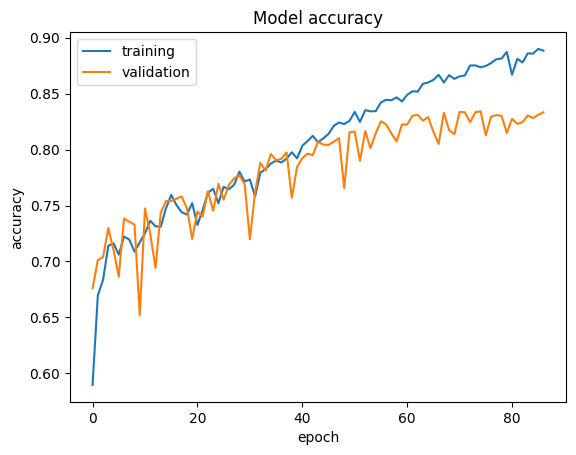

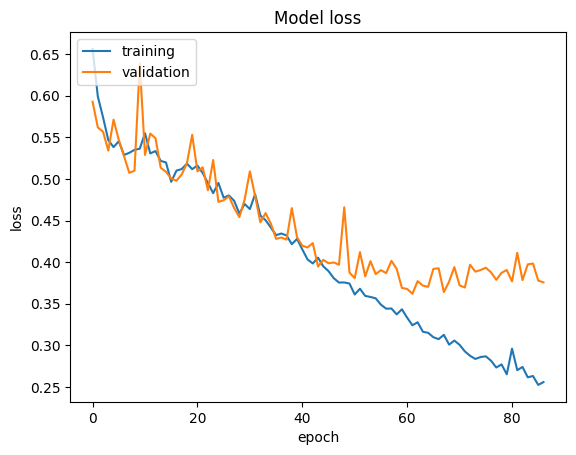

Training accuracy:  88.8310194015503
Validation accuracy:  83.33333134651184


In [22]:
import matplotlib.pyplot as plt
from sklearn import metrics

# list all data in history
print(history_m.history.keys())
# summarize history for accuracy
plt.plot(history_m.history['accuracy'])
plt.plot(history_m.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['training', 'validation'], loc='upper left')
plt.savefig('acc_healthy.pdf')
plt.show()

# summarize history for loss
plt.plot(history_m.history['loss'])
plt.plot(history_m.history['val_loss'])
plt.title('Model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['training', 'validation'], loc='upper left')
plt.savefig('loss_healthy.pdf')
plt.show()


print("Training accuracy: ", history_m.history['accuracy'][-1]*100)
print("Validation accuracy: ", history_m.history['val_accuracy'][-1]*100)


135/135 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
0.9017809313018826


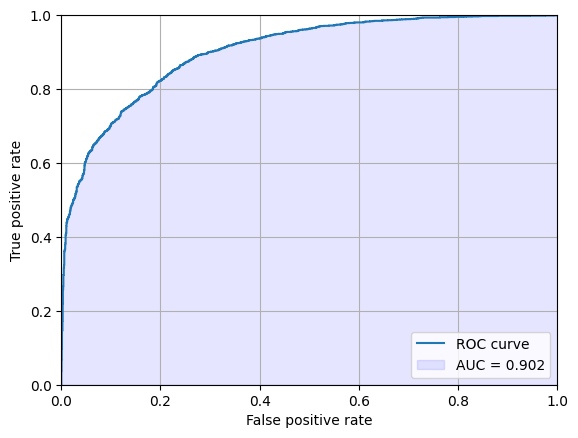

In [23]:
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
y_pred_keras = model1.predict(x_test1).ravel()
fpr_keras, tpr_keras, thresholds_keras = roc_curve(y_test1, y_pred_keras)
auc_keras = auc(fpr_keras, tpr_keras)
print(auc_keras)
plt.plot(fpr_keras, tpr_keras, label='ROC curve')
plt.fill_between(fpr_keras, tpr_keras, 0, color='blue', alpha=.1, label='AUC = {:.3f}'.format(auc_keras))
plt.axis([0, 1, 0, 1])
plt.grid()
plt.legend(loc='lower right')
plt.ylabel('True positive rate')
plt.xlabel('False positive rate')
plt.savefig('ROC_hea_unhea.pdf')



135/135 - 1s - 4ms/step
Accuracy: 0.807176
Specificity: 0.880092
Precision: 0.856517
Sensitivity: 0.732553
F1 score: 0.789700
Cohens kappa: 0.613660
ROC AUC: 0.901781
Total Samples Test:  4320
[[1923  262]
 [ 571 1564]]


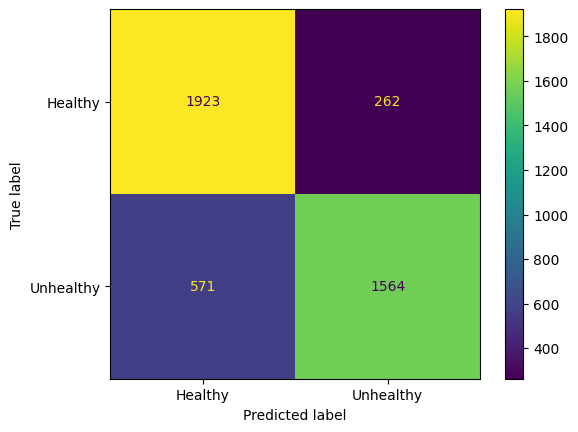

In [24]:
import matplotlib.pyplot as plt
from sklearn import metrics

prob = model1.predict(x_test1,verbose = 2)
pred = (prob > 0.5).astype("int32")


#(loss, acc) = conv_model.evaluate(x_test1, y_test1)
#print("Accuracy", acc*100)


# reduce to 1d array
yhat_probs = prob[:, 0]
yhat_classes = pred[:, 0]

cm= metrics.confusion_matrix(y_test1,pred)
# accuracy: (tp + tn) / (p + n)
accuracy = metrics.accuracy_score(y_test1,pred)
print('Accuracy: %f' % accuracy)
# sensitivity = tp(tp+fn)
#sensitivity = metrics.specificity_score(y_test1, pred)
# specificity = tn(tn+fp)
specificity = cm[0,0]/(cm[0,0]+cm[0,1])
print('Specificity: %f' % specificity)
# precision tp / (tp + fp)
precision = metrics.precision_score(y_test1,pred)
print('Precision: %f' % precision)
# recall/sensitivity: tp / (tp + fn)
recall = metrics.recall_score(y_test1, pred)
print('Sensitivity: %f' % recall)
# f1: 2 tp / (2 tp + fp + fn)
f1 = metrics.f1_score(y_test1, pred)
print('F1 score: %f' % f1)
# kappa
kappa = metrics.cohen_kappa_score(y_test1, pred)
print('Cohens kappa: %f' % kappa)
# ROC AUC
auc = metrics.roc_auc_score(y_test1, prob)
print('ROC AUC: %f' % auc)

print("Total Samples Test: ", np.shape(y_test1)[0])
labels=["Healthy", "Unhealthy"]
cm=metrics.confusion_matrix(y_test1,pred)
disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot()
plt.savefig('confusion_matrix_healthy_lstm.pdf')
print(cm)

##Inception model

In [25]:
# GRADED FUNCTION: convolutional_model
from tensorflow import keras
import tensorflow.keras.layers as tfl
from tensorflow.keras.layers import *
from tensorflow.keras.utils import *
from time import time


# Architecture of the model
def inception_module(layer, f1, f2, f3, f4):
    conv1 = Conv1D(f1, 1, activation='relu', padding='same')(layer)
    conv2 = Conv1D(f1, 1, activation='relu', padding='same')(layer)
    conv3 = Conv1D(f1, 1, activation='relu', padding='same')(layer)
    maxp = MaxPool1D(pool_size=3, strides=1, padding='same')(layer)

    conv2 = Conv1D(f2, 3, activation='relu', padding='same')(conv2)
    conv3 = Conv1D(f3, 5, activation='relu', padding='same')(conv3)
    conv4 = Conv1D(f4, 1, activation='relu', padding='same')(maxp)

    return Concatenate()([conv1, conv2, conv3, conv4])

def build_incep(input_shape,  x_train,y_train,test_data):
    start=time()
    input_signal = Input(shape=input_shape)


    incept = inception_module(input_signal, 16, 32, 64, 16)
    conv = Conv1D(96, 5, activation='relu', padding='same')(incept)
    conv = Conv1D(64, 3, activation='relu', padding='same')(conv)
    gru = GRU(64, return_sequences=True)(conv)

    maxp = MaxPool1D()(gru)

    incept = inception_module(maxp, 8, 16, 32, 8)
    conv = Conv1D(48, 5, activation='relu', padding='same')(incept)
    conv = Conv1D(32, 3, activation='relu', padding='same')(conv)
    gru = GRU(32, return_sequences=True)(conv)

    maxp = MaxPool1D()(gru)

    incept = inception_module(maxp, 2, 4, 8, 2)
    conv = Conv1D(12, 5, activation='relu', padding='same')(incept)
    conv = Conv1D(8, 3, activation='relu', padding='same')(conv)
    gru = GRU(8, return_sequences=True)(conv)

    flat = Flatten()(gru)
    #output1 = Dense(8, activation='relu')(flat)
    output = Dense(1, activation='sigmoid')(flat)


    #if 'model' in globals() or 'model' in locals():
    #    del model

    model = keras.Model(inputs=input_signal, outputs=output)
    model.summary()
    init_weights = model.get_weights()

    #plot_model(model, show_shapes=True)

    #compile
    opt = tf.keras.optimizers.Adam( learning_rate=0.001, beta_1=0.9, beta_2=0.999, epsilon=1e-07)

    #compile
    model.compile(optimizer = 'adam',
                  loss='binary_crossentropy',
              metrics=['accuracy'])

    model.summary()

    early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, verbose=2)
    history_m = model.fit(x_train,y_train, epochs=150, validation_split = 0.2, callbacks=[early_stopping] ,batch_size = 64, shuffle = True)

    t=time()-start
    print('Total training time:', t)
    history_m.history['time']=t

    return model, history_m


In [26]:
conv_model, history = build_incep((1024,1), x_train1, y_train1, (x_test1,y_test1))

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 1024, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_21 (Conv1D)  │ (None, 1024, 16)  │         32 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_22 (Conv1D)  │ (None, 1024, 16)  │         32 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_4     │ (None, 1024, 1)   │          0 │ input_layer_3[0]… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_20 (Conv1D)  │ (None, 1024, 16)  │         32 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_23 (Conv1D)  │ (None, 1024, 32)  │      1,568 │ conv1d_21[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_24 (Conv1D)  │ (None, 1024, 64)  │      5,184 │ conv1d_22[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_25 (Conv1D)  │ (None, 1024, 16)  │         32 │ max_pooling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 1024, 128) │          0 │ conv1d_20[0][0],  │
│ (Concatenate)       │                   │            │ conv1d_23[0][0],  │
│                     │                   │            │ conv1d_24[0][0],  │
│                     │                   │            │ conv1d_25[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_26 (Conv1D)  │ (None, 1024, 96)  │     61,536 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_27 (Conv1D)  │ (None, 1024, 64)  │     18,496 │ conv1d_26[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 1024, 64)  │     24,960 │ conv1d_27[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 512, 64)   │          0 │ gru[0][0]         │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_29 (Conv1D)  │ (None, 512, 8)    │        520 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_30 (Conv1D)  │ (None, 512, 8)    │        520 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_6     │ (None, 512, 64)   │          0 │ max_pooling1d_5[… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_28 (Conv1D)  │ (None, 512, 8)    │        520 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_31 (Conv1D)  │ (None, 512, 16)   │        400 │ conv1d_29[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_32 (Conv1D)  │ (None, 512, 32)   │      1,312 │ conv1d_30[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_33 (Conv1D)  │ (None, 512, 8)    │        520 │ max_pooling1d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 512, 64)   │          0 │ conv1d_28[0][0],  │
│ (Concatenate)       │                   │            │ conv1d_31[0][0],

 Total params: 146,177 (571.00 KB)

 Trainable params: 146,177 (571.00 KB)

 Non-trainable params: 0 (0.00 B)

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 1024, 1)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_21 (Conv1D)  │ (None, 1024, 16)  │         32 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_22 (Conv1D)  │ (None, 1024, 16)  │         32 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_4     │ (None, 1024, 1)   │          0 │ input_layer_3[0]… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_20 (Conv1D)  │ (None, 1024, 16)  │         32 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_23 (Conv1D)  │ (None, 1024, 32)  │      1,568 │ conv1d_21[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_24 (Conv1D)  │ (None, 1024, 64)  │      5,184 │ conv1d_22[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_25 (Conv1D)  │ (None, 1024, 16)  │         32 │ max_pooling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 1024, 128) │          0 │ conv1d_20[0][0],  │
│ (Concatenate)       │                   │            │ conv1d_23[0][0],  │
│                     │                   │            │ conv1d_24[0][0],  │
│                     │                   │            │ conv1d_25[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_26 (Conv1D)  │ (None, 1024, 96)  │     61,536 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_27 (Conv1D)  │ (None, 1024, 64)  │     18,496 │ conv1d_26[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 1024, 64)  │     24,960 │ conv1d_27[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 512, 64)   │          0 │ gru[0][0]         │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_29 (Conv1D)  │ (None, 512, 8)    │        520 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_30 (Conv1D)  │ (None, 512, 8)    │        520 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_6     │ (None, 512, 64)   │          0 │ max_pooling1d_5[… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_28 (Conv1D)  │ (None, 512, 8)    │        520 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_31 (Conv1D)  │ (None, 512, 16)   │        400 │ conv1d_29[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_32 (Conv1D)  │ (None, 512, 32)   │      1,312 │ conv1d_30[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_33 (Conv1D)  │ (None, 512, 8)    │        520 │ max_pooling1d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 512, 64)   │          0 │ conv1d_28[0][0],  │
│ (Concatenate)       │                   │            │ conv1d_31[0][0],

 Total params: 146,177 (571.00 KB)

 Trainable params: 146,177 (571.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
216/216 ━━━━━━━━━━━━━━━━━━━━ 33s 99ms/step - accuracy: 0.5228 - loss: 0.6863 - val_accuracy: 0.6962 - val_loss: 0.5692
Epoch 2/150
216/216 ━━━━━━━━━━━━━━━━━━━━ 38s 88ms/step - accuracy: 0.7076 - loss: 0.5483 - val_accuracy: 0.7260 - val_loss: 0.4946
Epoch 3/150
216/216 ━━━━━━━━━━━━━━━━━━━━ 22s 95ms/step - accuracy: 0.7293 - loss: 0.4996 - val_accuracy: 0.7393 - val_loss: 0.4816
Epoch 4/150
216/216 ━━━━━━━━━━━━━━━━━━━━ 19s 89ms/step - accuracy: 0.7526 - loss: 0.4766 - val_accuracy: 0.7497 - val_loss: 0.4747
Epoch 5/150
216/216 ━━━━━━━━━━━━━━━━━━━━ 22s 95ms/step - accuracy: 0.7640 - loss: 0.4598 - val_accuracy: 0.7743 - val_loss: 0.4560
Epoch 6/150
216/216 ━━━━━━━━━━━━━━━━━━━━ 20s 92ms/step - accuracy: 0.7686 - loss: 0.4531 - val_accuracy: 0.7514 - val_loss: 0.4784
Epoch 7/150
216/216 ━━━━━━━━━━━━━━━━━━━━ 20s 91ms/step - accuracy: 0.7764 - loss: 0.4464 - val_accuracy: 0.7798 - val_loss: 0.4311
Epoch 8/150
216/216 ━━━━━━━━━━━━━━━━━━━━ 21s 93ms/step - accuracy: 0.7889 - loss: 0

In [ ]:
model1 = tf.keras.models.load_model('/content/drive/MyDrive/ML/H&U_classification/lstm/model_v4.h5')
history=np.load('/content/drive/MyDrive/ML/H&U_classification/lstm/ver4_history.npy',allow_pickle='TRUE').item()

x_test1 = np.loadtxt('/content/drive/MyDrive/ML/H&U_classification/lstm/xtest_data_ver4.csv', delimiter=',')
y_test1 = np.loadtxt('/content/drive/MyDrive/ML/H&U_classification/lstm/ytest_data_ver4.csv', delimiter=',')